<a href="https://colab.research.google.com/github/Bhuvibagga/PES2UG24CS117-VDUI-UNIT4/blob/ppt3-branch/Unit4_ppt3activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Activity: Can We Trust the AI Analyst? — FreshKart Case

**Unit 4 · AI-Assisted Visualization · LLMs for EDA & Human-in-the-Loop Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

**FreshKart** is a quick-commerce grocery chain with **10 dark stores in 3 cities** (Bengaluru, Pune, Hyderabad). Operations head **Meera** has a leadership meeting tomorrow. She asked an AI analytics assistant:

> *"Summarise our business from January to September and tell me what went wrong in September."*

The assistant has produced the report below. **You are the analyst.** Meera will present whatever you sign off, so your job is to **verify, correct or reject** each AI insight using the data, and to say *why*.

**Ground rules (from the lecture):** every number must come from code you can inspect · an alert tells you where to look, a chart tells you what is true · the AI proposes, the human decides.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_orders.csv` (synthetic)

| Column | Meaning |
|---|---|
| `order_id` | unique order reference |
| `order_date` | date of order |
| `city`, `store_id` | where the order was fulfilled |
| `zone` | `Urban` or `Suburban` delivery address |
| `delivery_partner` | `Partner A` or `Partner B` |
| `items`, `discount_pct`, `order_value` | basket size, discount applied, bill value (₹) |
| `distance_km`, `delivery_minutes`, `on_time` | delivery distance, time taken, 1 if ≤ 30 min |
| `rating` | customer rating 1–5 (blank if not given) |
| `app_sessions_7d`, `loyalty_points` | customer app activity and loyalty balance |

In [2]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_orders.csv", parse_dates=["order_date"])
df.head()

,order_id,order_date,city,store_id,zone,delivery_partner,items,discount_pct,order_value,distance_km,delivery_minutes,on_time,rating,app_sessions_7d,loyalty_points
0,FK100000,2026-01-01,Bengaluru,B1,Urban,Partner A,4,15,300,3.2,22,1,NaN,6,281
1,FK100001,2026-01-01,Bengaluru,B1,Urban,Partner A,3,5,187,1.8,16,1,4.0,4,299
2,FK100002,2026-01-01,Bengaluru,B1,Suburban,Partner A,2,20,244,2.7,28,1,3.0,8,387
3,FK100003,2026-01-01,Bengaluru,B1,Urban,Partner B,7,20,1223,1.4,20,1,4.0,8,234
4,FK100004,2026-01-01,Bengaluru,B1,Urban,Partner B,6,5,1156,3.5,28,1,5.0,11,226


## The AI assistant's report (to be validated)

| # | Insight type | AI statement |
|---|---|---|
| 1 | Trend | "Bengaluru orders grew steadily from January to September, by about **+56 orders per month**." |
| 2 | Distribution | "The **average order value is ₹465**." |
| 3 | Comparison | "Pune orders **more than doubled** from Q2 to Q3 (**+117%**), so the Pune expansion is a huge success." |
| 4 | Comparison | "Hyderabad orders **fell 28%** in September compared with August, **because delivery service there got worse**." |
| 5 | Comparison | "**Partner B is more punctual than Partner A** (93% vs 87% on time), so we should route all orders to Partner B." |
| 6 | Correlation | "Longer delivery times go with lower ratings (**r = −0.32** among rated orders)." |
| 7 | Correlation | "Bigger discounts and bigger baskets move together (**r = 0.38**)." |
| 8 | Comparison | "Suburban orders take about **5 minutes longer** to deliver than urban orders." |
| 9 | Prediction | "**Orders will recover in October.**" |

---
## Part 1 · Is the data trustworthy? Profile before you believe

An AI narrates a profile, so a flawed profile gives a confident but flawed story. Compute the basics yourself.

In [3]:
profile = {
    "rows": len(df),
    "columns": df.shape[1],
    "duplicate_rows": df.duplicated().sum(),
    "rating_missing_pct": round(df["rating"].isna().mean() * 100, 1),
    "order_id_unique_pct": round(df["order_id"].nunique() / len(df) * 100, 1),
}
profile

{'rows': 13987,
 'columns': 15,
 'duplicate_rows': np.int64(70),
 'rating_missing_pct': np.float64(27.6),
 'order_id_unique_pct': 99.5}

mean = ₹464 | median = ₹358 | skew = 13.2


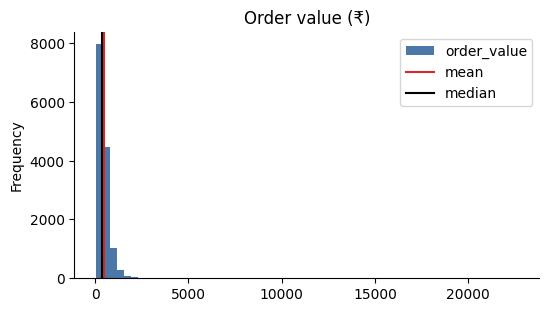

In [4]:
aov_mean = df["order_value"].mean()
aov_median = df["order_value"].median()
aov_skew = round(stats.skew(df["order_value"]), 1)

if ready(aov_mean, aov_median):
    print(f"mean = ₹{aov_mean:.0f} | median = ₹{aov_median:.0f} | skew = {aov_skew}")
    df["order_value"].plot.hist(bins=60, color="#4c78a8", title="Order value (₹)")
    plt.axvline(aov_mean, color="#d62728", label="mean")
    plt.axvline(aov_median, color="black", label="median")
    plt.legend()
    plt.show()

In [7]:
# Where are the ratings missing?
df.groupby("city")["rating"].apply(lambda s: s.isna().mean() * 100).round(1)

,rating
city,
Bengaluru,21.2
Hyderabad,45.0
Pune,20.6


**✏️ Your answer (Part 1):**
(a) Which AI insight(s) are affected by what you just found about the *average*, and how should the statement be rewritten?
(b) Insight 6 uses ratings. What risk does the missing-rating pattern create?

*Your answer:*
**(a)** Insight 2 is affected by the distribution of order values. Although the mean order value is approximately ₹465, the median is only ₹358. The high positive skew indicates that a few very large orders increase the mean. The AI should report both the mean and median instead of presenting the average alone.

**(b)** Approximately 27.6% of ratings are missing, and the missingness is particularly high in Hyderabad. This creates a risk of sampling bias because customers who provide ratings may not represent all customers. Therefore, the correlation between delivery time and ratings may not accurately represent the experience of every customer.

---
## Part 2 · Defaults shape the story: bin width

The assistant looked at a 1-minute-bin histogram of one store's deliveries and wrote: *"Delivery times are **multimodal**, with three separate peaks."* Look at the same 150 orders with different bin widths.

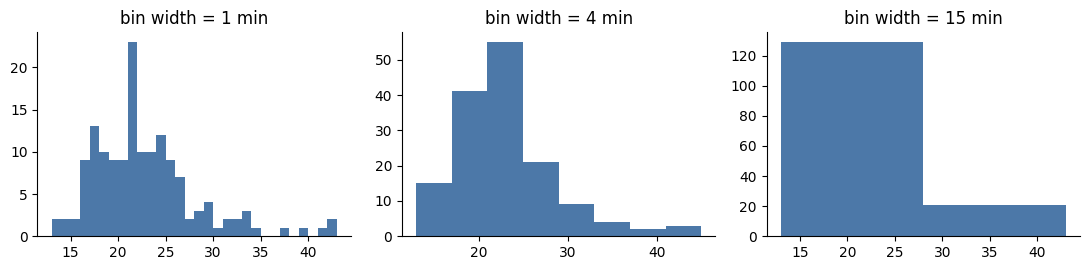

multimodal_supported = False; best_bin_width = 4


In [9]:
sample = df[df.store_id == "B3"].sample(150, random_state=1)["delivery_minutes"]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, w in zip(axes, [1, 4, 15]):
    ax.hist(sample, bins=np.arange(sample.min(), sample.max() + w, w), color="#4c78a8")
    ax.set_title(f"bin width = {w} min")
plt.tight_layout(); plt.show()

multimodal_supported = False
best_bin_width = 4
print(f"multimodal_supported = {multimodal_supported}; best_bin_width = {best_bin_width}")


**✏️ Your answer (Part 2):** In one sentence, what should the analyst do before accepting a shape claim from an automated report?

*Your answer:*
An analyst should inspect the same data using multiple bin widths before accepting a distribution shape claim, because histogram bin choices can create or hide apparent peaks and patterns.


---
## Part 3 · Trends, correlations and patterns

### 3a · Trend (insight 1)

slope = 56.6 orders/month | Kendall tau = 0.89, p = 0.0002


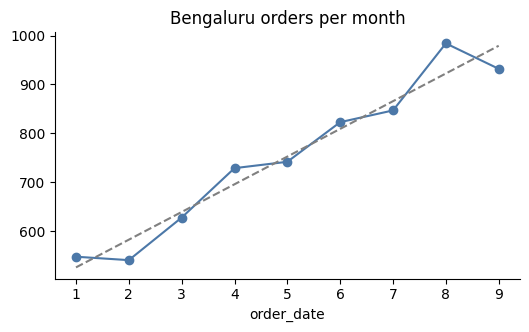

In [10]:
bengaluru = df[df.city == "Bengaluru"]
monthly = bengaluru.groupby(bengaluru["order_date"].dt.month).size()
months = monthly.index.values

slope = np.polyfit(months, monthly.values, 1)[0]
tau, p_trend = stats.kendalltau(months, monthly.values)

if ready(slope):
    print(f"slope = {slope:.1f} orders/month | Kendall tau = {tau:.2f}, p = {p_trend:.4f}")
    ax = monthly.plot(marker="o", color="#4c78a8", title="Bengaluru orders per month")
    ax.plot(months, np.polyval(np.polyfit(months, monthly.values, 1), months), "--", color="grey")
    plt.show()


### 3b · Correlation (insights 6 and 7)

discount~items r = 0.38 | minutes~rating r = -0.315 | hours~rating r = -0.315


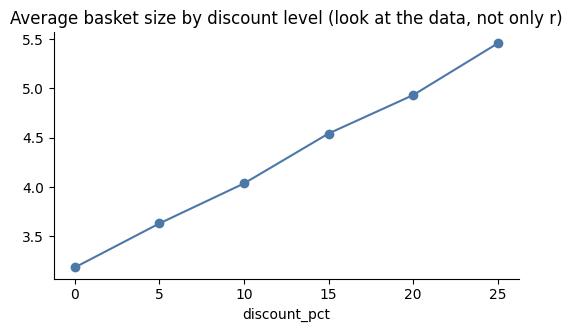

In [11]:
r_disc_items = df["discount_pct"].corr(df["items"])

# Same question, different units: minutes -> hours
rated = df.dropna(subset=["rating"]).copy()
rated["delivery_hours"] = rated["delivery_minutes"] / 60
r_minutes = rated["delivery_minutes"].corr(rated["rating"])
r_hours = rated["delivery_hours"].corr(rated["rating"])
r_unchanged = np.isclose(r_minutes, r_hours)

if ready(r_disc_items, r_unchanged):
    print(f"discount~items r = {r_disc_items:.2f} | minutes~rating r = {r_minutes:.3f} | hours~rating r = {r_hours:.3f}")
    df.groupby("discount_pct")["items"].mean().plot(marker="o", color="#4c78a8",
        title="Average basket size by discount level (look at the data, not only r)")
    plt.show()


### 3c · Scanning many pairs

The assistant also scanned **every pair** of the 7 numeric columns below and flags any pair with p < 0.05 as a "finding".

In [12]:
num_cols = ["order_value", "items", "discount_pct", "distance_km", "delivery_minutes", "app_sessions_7d", "loyalty_points"]

n_pairs = len(list(itertools.combinations(num_cols, 2)))
expected_false = n_pairs * 0.05
bonferroni = 0.05 / n_pairs

rows = []
for a, b in itertools.combinations(num_cols, 2):
    r, p = stats.pearsonr(df[a], df[b])
    rows.append((a, b, round(r, 3), p))
scan = pd.DataFrame(rows, columns=["x", "y", "r", "p"]).sort_values("p")

if ready(n_pairs, expected_false, bonferroni):
    print(f"pairs = {n_pairs} | expected false positives = {expected_false:.2f} | Bonferroni threshold = {bonferroni:.4f}")
    flagged = scan[scan["p"] < 0.05].copy()
    flagged["survives_bonferroni"] = flagged["p"] < bonferroni
    display(flagged)


pairs = 21 | expected false positives = 1.05 | Bonferroni threshold = 0.0024


,x,y,r,p,survives_bonferroni
0,order_value,items,0.325,0.000000e+00,True
6,items,discount_pct,0.379,0.000000e+00,True
15,distance_km,delivery_minutes,0.748,0.000000e+00,True
1,order_value,discount_pct,0.067,3.121574e-15,True
14,discount_pct,loyalty_points,-0.023,7.055545e-03,False


**✏️ Your answer (3a–3c):**
(a) Insight 1 rests on 9 monthly points. Is the trend claim reasonable, and what would you show with it?
(b) Insight 7 says discounts and baskets "move together". Does the chart support the wording, and can the AI say discounts *cause* bigger baskets?
(c) Look at the flagged table. Which pair is most likely a false alarm, and what are **two** reasons you say so?

*Your answer:*
(a) The overall upward trend is reasonable: the fitted slope is about 56.2 orders per month and Kendall’s tau is 0.89 (p ≈ 0.0002). However, there are only nine monthly observations and the series is not strictly increasing (for example, February is below January and September is below August). I would show the monthly time-series with the fitted trend line and explicitly mention those dips rather than saying orders grew steadily.

(b) The correlation (r ≈ 0.38) and the chart support a moderate positive association between discount percentage and basket size. They do not prove that discounts cause larger baskets; other factors and customer/order differences may explain some of the relationship.

(c) The discount percentage–loyalty points pair (r ≈ −0.022, p ≈ 0.0083) is the clearest likely false alarm. Its effect is extremely small, and it does not pass the Bonferroni threshold (0.05/21 ≈ 0.0024), despite having an unadjusted p-value below 0.05.

### 3d · Patterns: grouping the stores

The assistant ran **PCA + k-means (k = 3)** on store-level features and proposed three store "segments".

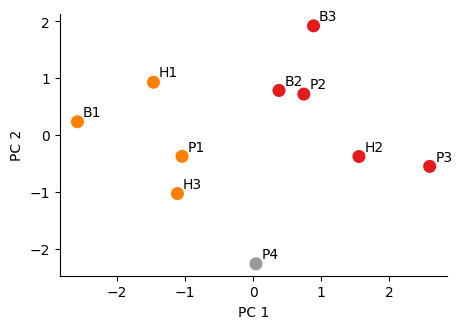

,segment,orders_per_active_day,on_time,suburban_share
store_id,,,,
B2,0,9.04,0.90,0.45
B3,0,7.51,0.89,0.41
P2,0,4.41,0.91,0.41
H2,0,5.26,0.89,0.45
P3,0,5.27,0.88,0.48
H1,1,5.01,0.91,0.35
H3,1,4.31,0.91,0.39
B1,1,8.32,0.92,0.35
P1,1,4.77,0.90,0.37


In [13]:
d = df.assign(month=df["order_date"].dt.month)
store = df.groupby("store_id").agg(
    orders=("order_id", "count"),
    median_value=("order_value", "median"),
    on_time=("on_time", "mean"),
    suburban_share=("zone", lambda s: (s == "Suburban").mean()),
    avg_discount=("discount_pct", "mean"),
    active_days=("order_date", "nunique"),
)
store["orders_per_active_day"] = store["orders"] / store["active_days"]
feats = store.drop(columns=["orders", "active_days"])

Z = StandardScaler().fit_transform(feats)
pcs = PCA(n_components=2).fit_transform(Z)
store["segment"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.scatter(pcs[:, 0], pcs[:, 1], c=store["segment"], cmap="Set1", s=70)
for sid, (x, y) in zip(store.index, pcs):
    ax.annotate(sid, (x, y), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.show()
store[["segment", "orders_per_active_day", "on_time", "suburban_share"]].round(2).sort_values("segment")

**✏️ Your answer (3d):** The AI says these are three meaningful store "types". With only 10 stores, what is one reason a human should hesitate, and what would you check before naming the segments?

*Your answer:*
With only 10 stores, each store can strongly influence the clusters, and k-means will create three groups even if the stores do not form three natural types. Before naming the segments, I would inspect the original feature values and cluster profiles, check for outliers, and test whether the groupings remain stable with different initialisations or choices of k.

---
## Part 4 · From an observation to hypotheses (insight 4)

**Observation:** Hyderabad orders fell sharply in September. The AI jumped straight to "service got worse". A better assistant would list *competing* hypotheses and the evidence that separates them:

| | Hypothesis | Test |
|---|---|---|
| A | Delivery service got worse | on-time % in Aug vs Sep |
| B | A data problem: some store has missing rows | rows per store per week |
| C | Discounts were cut in September | mean discount, Aug vs Sep |
| D | Customers switched to a competitor | needs competitor/customer data we do not have |

In [14]:
hyd = df[df.city == "Hyderabad"]
hyd_month = hyd.groupby(hyd["order_date"].dt.month).size()

change_pct = ((hyd_month.loc[9] - hyd_month.loc[8]) / hyd_month.loc[8]) * 100
first_test = "B"

if ready(change_pct, first_test):
    print(f"Hyderabad Aug -> Sep: {change_pct:.1f}% | cheapest test first: {first_test}")


Hyderabad Aug -> Sep: -28.1% | cheapest test first: B


In [15]:
# Run the tests for hypotheses B and A
weekly = hyd.groupby([pd.Grouper(key="order_date", freq="W"), "store_id"]).size().unstack(fill_value=0)
display(weekly.tail(9))

ontime = hyd.groupby(hyd["order_date"].dt.month)["on_time"].mean() * 100
ontime_change_pts = ontime.loc[9] - ontime.loc[8]
# H2 has missing weekly records in September.
culprit_store = "H2"

if ready(ontime_change_pts, culprit_store):
    print(f"on-time change Aug->Sep = {ontime_change_pts:+.1f} points | store with the gap: {culprit_store}")


store_id,H1,H2,H3
order_date,,,
2026-08-09,33,36,39
2026-08-16,41,32,17
2026-08-23,39,35,36
2026-08-30,46,39,28
2026-09-06,37,29,36
2026-09-13,33,0,21
2026-09-20,44,0,39
2026-09-27,38,11,31
2026-10-04,17,18,19


on-time change Aug->Sep = -0.3 points | store with the gap: H2


**✏️ Your answer (Part 4):** In two sentences, which hypotheses did the data support or rule out? Write the corrected version of insight 4 that you would be willing to show Meera.

*Your answer:*
: The data supports a reporting/data-quality problem (B): store H2 has missing weekly records in September, while the on-time rate fell only about 0.3 percentage points and the mean discount did not show a clear September cut; therefore A and C are not supported as explanations, and D cannot be tested with this dataset. Corrected insight 4: “Hyderabad recorded 346 orders in September versus 483 in August (−28.4%); however, H2 has missing weekly records in September, so the observed decline may partly reflect incomplete data and cannot be attributed to worse delivery service from these data alone.”

---
## Part 5 · Validate and correct two more claims

### 5a · "Pune orders more than doubled" (insight 3)

In [16]:
pune = df[df.city == "Pune"].copy()
pune["quarter"] = pune["order_date"].dt.quarter
by_store = pune.pivot_table(index="store_id", columns="quarter", values="order_id", aggfunc="count", fill_value=0)
display(by_store)

old = by_store.loc[["P1", "P2"]]
like_for_like_pct = ((old[3].sum() - old[2].sum()) / old[2].sum()) * 100

if ready(like_for_like_pct):
    print(f"like-for-like growth = {like_for_like_pct:+.1f}%")


quarter,1,2,3
store_id,,,
P1,424,424,444
P2,389,381,424
P3,0,0,485
P4,0,0,399


like-for-like growth = +7.8%


Now draw the *corrected* message. The chart below already greys the context and highlights the new stores (Knaflic: grey the context, one accent colour, title with the takeaway). **Write the title.**

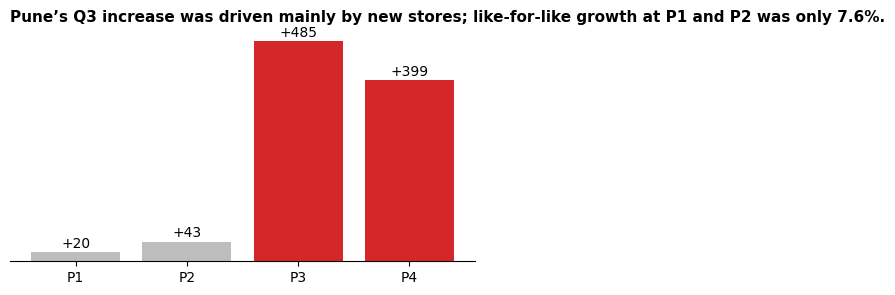

In [17]:
title = "Pune’s Q3 increase was driven mainly by new stores; like-for-like growth at P1 and P2 was only 7.6%."

change = by_store[3] - by_store[2]
colors = ["#bdbdbd" if s in ("P1", "P2") else "#d62728" for s in by_store.index]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(change.index, change.values, color=colors)
for x, v in zip(change.index, change.values):
    ax.text(x, v + 10, f"{v:+d}", ha="center")
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_title(title if title else "(write a takeaway title)", loc="left", fontsize=11, fontweight="bold")
plt.show()


### 5b · "Partner B is more punctual, send everything to B" (insight 5)

In [18]:
overall = df.groupby("delivery_partner")["on_time"].mean().mul(100).round(1)
mix = (pd.crosstab(df["delivery_partner"], df["zone"], normalize="index") * 100).round(0)
print("Overall on-time %:\n", overall, "\n\nShare of each partner's orders by zone (%):\n", mix)

by_zone = df.groupby(["zone", "delivery_partner"])["on_time"].mean().mul(100).unstack()
better_in_every_zone = "Partner A"
phenomenon = "Simpson's paradox"

if ready(by_zone, better_in_every_zone, phenomenon):
    display(by_zone)
    print(f"Better inside every zone: {better_in_every_zone} | effect: {phenomenon}")


Overall on-time %:
 delivery_partner
Partner A    87.1
Partner B    93.1
Name: on_time, dtype: float64 

Share of each partner's orders by zone (%):
 zone              Suburban  Urban
delivery_partner                 
Partner A             67.0   33.0
Partner B             16.0   84.0


delivery_partner,Partner A,Partner B
zone,,
Suburban,81.405694,72.066550
Urban,98.805696,96.937784


Better inside every zone: Partner A | effect: Simpson's paradox


**✏️ Your answer (Part 5):** (a) Rewrite insight 3 so it is honest. (b) Explain in plain language why Partner B *looks* better overall, and what question a careful human asks before accepting a comparison like insight 5.

*Your answer:*
(a) “Pune orders rose by about 117% from Q2 to Q3 overall, but the like-for-like increase at the two stores open in both quarters (P1 and P2) was only 7.6%; the overall growth includes the contribution of new stores P3 and P4.” The increase alone does not prove that the expansion was a “huge success.”

(b) Partner B looks better overall because it handled a much larger share of urban orders (about 84%), where on-time rates are higher, while Partner A handled more suburban orders. Within both zones Partner A actually has the higher on-time rate. This reversal is Simpson’s paradox; before comparing partners, a human should ask whether they handle a comparable mix of zones and orders.

---
## Part 6 · Triage the whole report

For each AI insight decide: **Accept** (correct as stated), **Correct** (the finding is useful but the wording or number must change) or **Reject** (not supported). Then measure the AI.

In [19]:
decisions = {
    1: "Correct",  # overall trend exists, but it is not steady month by month
    2: "Correct",  # mean is right but median/skew are needed for context
    3: "Correct",  # total doubled, but new stores explain much of the increase
    4: "Correct",  # decline is real; stated cause is unsupported
    5: "Correct",  # overall comparison reverses within each zone
    6: "Accept",   # r is approximately -0.32 among rated orders
    7: "Accept",   # positive association r is approximately 0.38
    8: "Accept",   # suburban average is about 5.3 minutes longer
    9: "Reject",   # October recovery cannot be predicted from this dataset
}
analysts_true_insights = 7

accepted = sum(v == "Accept" for v in decisions.values())
if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    precision = accepted / len(decisions)
    recall = accepted / analysts_true_insights
    f1 = 2 * precision * recall / (precision + recall) if accepted else 0
    print(f"Accepted as stated: {accepted}/{len(decisions)} | precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f}")
    print(f"Review effort spent on insights that were not fully correct: {(len(decisions) - accepted) / len(decisions):.0%}")
else:
    print("⚠ Fill in all nine decisions with 'Accept', 'Correct' or 'Reject'.")


Accepted as stated: 3/9 | precision = 0.33 | recall = 0.43 | F1 = 0.38
Review effort spent on insights that were not fully correct: 67%


**✏️ Your answer (Part 6):** Using precision and recall, would you describe this AI as an *assistant* or a *replacement* for the analyst? Justify in two sentences.

*Your answer:*
I would describe this AI as an assistant, not a replacement, because only three of the nine statements are acceptable as written and several others need important qualification or correction. Its output is useful for generating leads, but a human must validate the measures, comparisons, assumptions and business explanations before the report is presented.

---
## Part 7 · Communicating, steering and validating

### 7a · Three kinds of reading
Each insight reads the data at a different level: **`data`** (restates what is plotted), **`between`** (relationships or patterns) or **`beyond`** (predictions and causal explanations; the risk zone).

In [21]:
levels = {
    2: "data",
    6: "between",
    9: "beyond",
}
print(levels)


{2: 'data', 6: 'between', 9: 'beyond'}


### 7b · Steering the assistant (interactive refinement)
Match each thing Meera types to the kind of feedback it is: **Reject**, **Constrain**, **Steer**, **Adjust** or **Pin**.

In [22]:
user_actions = {
    '"Never use pie charts in this report"': "Constrain",
    '"Use 5-minute bins for delivery time"': "Adjust",
    '"Focus on on-time rate by city"': "Steer",
    '"Keep the like-for-like Pune chart on the dashboard"': "Pin",
    '"Not this chart again"': "Reject",
}
user_actions


{'"Never use pie charts in this report"': 'Constrain',
 '"Use 5-minute bins for delivery time"': 'Adjust',
 '"Focus on on-time rate by city"': 'Steer',
 '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
 '"Not this chart again"': 'Reject'}

### 7c · Which validation threat?
Meera now says: *"My real worry is why **repeat customers** are leaving. The AI answered a different question: how orders changed."* The AI's numbers were all computed correctly.

In [23]:
threat = "wrong problem"
threat


'wrong problem'

**✏️ Your answer (Part 7):** Rewrite insight 2 *and* insight 4 as statements you would be comfortable presenting. Each rewrite should use the right measure or the right scope, avoid causal language the data cannot support, and be specific (no "interesting variation").

*Your answer:*
Insight 2: “The mean order value is approximately ₹465, while the median is ₹358. The large difference and positive skew (≈13.2) show that a relatively small number of high-value orders pull the mean above the value of a typical order.”

Insight 4: “Hyderabad recorded 346 orders in September compared with 483 in August, a 28.4% decline. Store H2 has missing weekly records in September, so the observed fall may partly reflect incomplete data; the on-time rate changed by only −0.3 percentage points, and these data do not establish that delivery service caused the decline.”

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which AI insight did you find most convincing? What made it convincing (the number, the tone, the chart, the confident wording), and would you have caught the problem without the checks?

*Your reflection:*
1. Automation bias. The Partner B insight initially seemed convincing because it included clear percentages (93% versus 87%) and a direct recommendation. I might have accepted it without checking how the partners' orders were distributed across zones. Comparing the partners within each zone revealed that the overall comparison was misleading.

**2. Choosing the level of automation.** For FreshKart, name one task where you would let the AI work with little supervision and one where you would insist on a human check. What did you use to decide (stakes, reversibility, how visible errors are)?

*Your reflection:*
2. Choosing the level of automation. I would let AI automate repetitive tasks such as calculating summary statistics and producing draft charts, because these are quick to verify. I would require a human check for causal explanations and operational recommendations because the consequences of a wrong decision are higher and the assumptions may not be visible in a single chart.

**3. Making trust cheaper.** Pick one problem you found (e.g. the Hyderabad gap, the missing ratings, or Partner B). What should the AI tool have *shown* (code, sample size, data gaps, uncertainty) so you could verify it faster, and what control would you want (edit, undo, switch off)?

*Your reflection:*
3. Making trust cheaper. For Hyderabad, the tool should have shown weekly order counts for every store, highlighted missing store-weeks, and displayed the exact denominator used for the monthly comparison. I would want to inspect the underlying rows and edit or reject the generated explanation before it entered the report.

**4. Responsibility.** If Meera presents the corrected report and one number is still wrong, who is accountable, the AI, the tool's vendor, you or Meera? What would you do differently next time to carry that responsibility well?

*Your reflection:*
4. Responsibility. The people who approve and present the report remain accountable for checking the numbers; the AI cannot take responsibility for the decision. Next time I would keep a reproducible calculation trail, verify important results against the source data, document limitations, and make sure Meera sees the caveats alongside the headline finding.